# Test the SDXL + IP-Adapter worker on Colab
Runtime → Change runtime type → **T4 GPU** (free tier works). Runs `handler.py` unchanged, so whatever passes here should behave the same on RunPod.

Upload `handler.py` and `requirements.txt` with the Files panel (left sidebar) before running.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -r requirements.txt

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Load the model (this is the cold-start cost)

In [2]:
import time, base64, io
t = time.perf_counter()
import handler  # loads SDXL + IP-Adapter at import, same as on RunPod
print(f'cold load: {time.perf_counter() - t:.1f}s')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

cold load: 81.1s


## 2. Text-only request

  0%|          | 0/30 [00:00<?, ?it/s]

seed 42 {'cold_load': 57218, 'fetch_input': 0, 'inference': 28436, 'encode': 490}


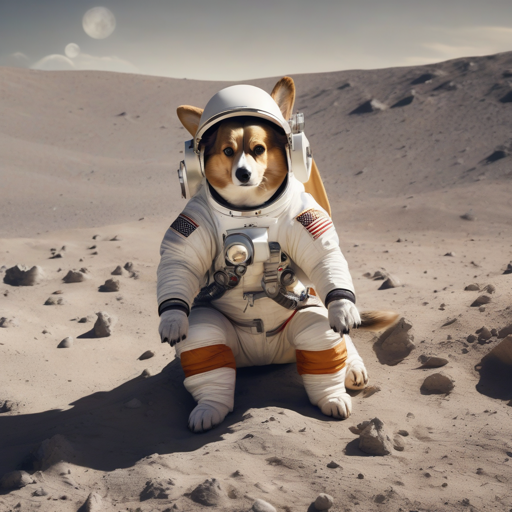

In [3]:
from PIL import Image
from IPython.display import display

def run(inp):
    out = handler.handler({'input': inp})
    if 'error' in out:
        raise RuntimeError(out['error'])
    print('seed', out['seed'], {k: round(v) for k, v in out['timings_ms'].items()})
    img = Image.open(io.BytesIO(base64.b64decode(out['image_base64'])))
    display(img.resize((512, 512)))
    return out

_ = run({'prompt': 'a corgi wearing a tiny astronaut helmet on the moon, cinematic, funny', 'seed': 42})

## 3. With a pet photo (IP-Adapter)
Upload a pet photo as `pet.jpg`. Try a few `ip_adapter_scale` values: higher keeps more identity, lower follows the prompt more.

ip_adapter_scale 0.4


  0%|          | 0/30 [00:00<?, ?it/s]

seed 42 {'cold_load': 0, 'fetch_input': 21, 'inference': 26970, 'encode': 356}


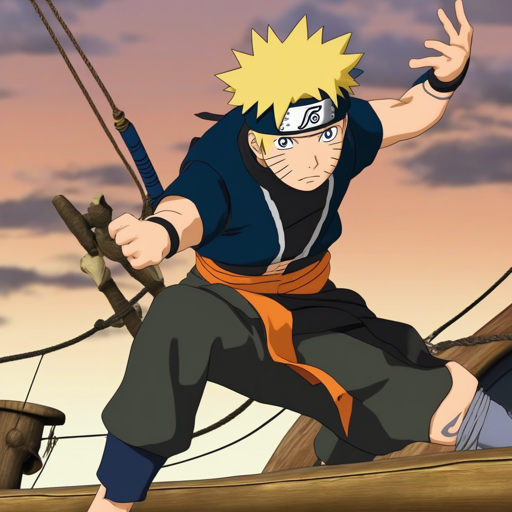

ip_adapter_scale 0.6


  0%|          | 0/30 [00:00<?, ?it/s]

seed 42 {'cold_load': 0, 'fetch_input': 15, 'inference': 27150, 'encode': 372}


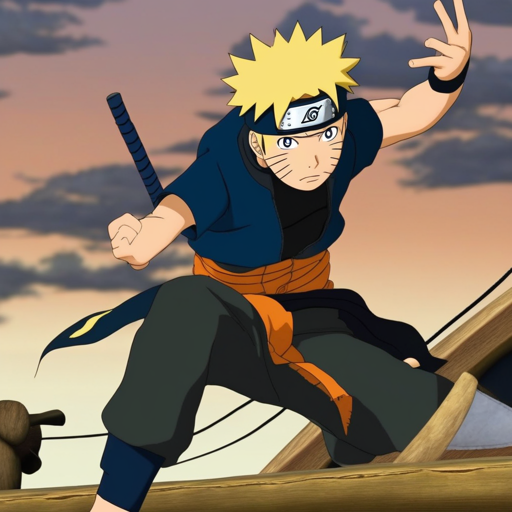

ip_adapter_scale 0.8


  0%|          | 0/30 [00:00<?, ?it/s]

seed 42 {'cold_load': 0, 'fetch_input': 19, 'inference': 26215, 'encode': 390}


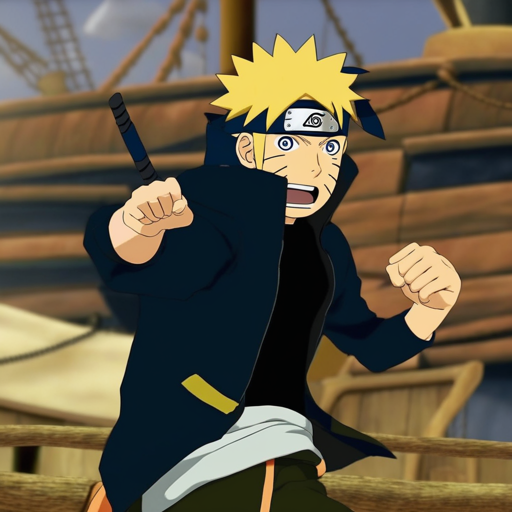

In [4]:
pet_b64 = base64.b64encode(open('naruto.png', 'rb').read()).decode()
for scale in [0.4, 0.6, 0.8]:
    print('ip_adapter_scale', scale)
    _ = run({'prompt': 'this naruto as a pirate captain on a ship, funny, cinematic', 'pet_image': pet_b64,
             'ip_adapter_scale': scale, 'seed': 42})

## 4. Quick warm-latency benchmark

In [5]:
import statistics
lat = [handler.handler({'input': {'prompt': 'a cat in a business suit', 'steps': 30, 'seed': i}})['timings_ms']['inference'] for i in range(5)]
print(f'inference p50 {statistics.median(lat):.0f} ms, max {max(lat):.0f} ms over {len(lat)} runs')

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

inference p50 26135 ms, max 26252 ms over 5 runs


## 5. (Optional) Expose as a RunPod-style API for the proxy server
The runpod SDK can serve the handler locally with the same `/run` + `/status` routes. A cloudflared tunnel gives it a public URL. Set `RUNPOD_BASE_URL=<that url>` in the server's `.env` and run the whole pipeline end to end, with no RunPod account needed.

If this command shows more than 0MiB, you should restart the notebook and delete the variables in order to publish the cloudflare URI.

In [1]:
!nvidia-smi --query-gpu=memory.used --format=csv

^C
memory.used [MiB]
0 MiB


In [ ]:
import time
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x cloudflared
import subprocess
subprocess.Popen(['./cloudflared', 'tunnel', '--url', 'http://localhost:8000'], stderr=open('tunnel.log', 'w'))
time.sleep(8)
!grep -o 'https://[a-z0-9-]*\.trycloudflare\.com' tunnel.log | head -1
!python handler.py --rp_serve_api --rp_api_host 0.0.0.0 --rp_api_port 8000

cloudflared: Text file busy
https://loops-treasures-cork-veterans.trycloudflare.com
utils.py            :164  2026-10-22 14:16:25,417 NumExpr defaulting to 2 threads.
I0000 00:00:1792678588.945708   11458 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792678594.125413   11458 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Loading pipeline components...: 100% 7/7 [00:04<00:00,  1.48it/s]
--- Starting Serverless Worker |  Version 1.7.9 ---
INFO   | Starting API server.
DEBUG  | Not deployed on RunPod serverless, pings will not be sent.
INFO:     Started server process [11458]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to 